In [206]:
import pandas as pd

df = pd.read_csv("healthcare_noshows_appointments.csv")

print(df.shape)
print('\n')
print(df.dtypes)

def print_stats(src_df: pd.DataFrame, tgt_column: str):
	tgt_column = tgt_column.strip()
	print(f"\nMax {tgt_column}:\t\t{src_df[tgt_column].max()}")
	print(f"Min {tgt_column}:\t\t{src_df[tgt_column].min()}")
	print(f"Average {tgt_column}:\t\t{src_df[tgt_column].mean():.1f}")
	print(f"{tgt_column} std:\t\t{src_df[tgt_column].std():.1f}\n")

(106987, 15)


PatientId         float64
AppointmentID       int64
Gender                str
ScheduledDay          str
AppointmentDay        str
Age                 int64
Neighbourhood         str
Scholarship          bool
Hipertension         bool
Diabetes             bool
Alcoholism           bool
Handcap              bool
SMS_received         bool
Showed_up            bool
Date.diff           int64
dtype: object


# 1. Temat projektu

Analiza czynników wpływających na realizację wizyt medycznych przez pacjentów oraz budowa modeli predykcyjnych wykrywających nieobecności pacjentów (No-Show).

# 2. Cel projektu

Celem projektu jest identyfikacja czynników wpływających na obecność pacjentów podczas umówionych wizyt medycznych oraz ocena możliwości przewidywania nieobecności na podstawie dostępnych danych demograficznych, zdrowotnych i organizacyjnych.

Dodatkowe cele obejmują:

- eksplorację struktury zbioru danych,
- identyfikację zależności między cechami,
- przeprowadzenie testów statystycznych weryfikujących postawione hipotezy,
- budowę modeli klasyfikacyjnych i regresyjnych,
- ocenę jakości uzyskanych modeli.


# 3. Opis zbioru danych

Zbiór danych zawiera informacje o 106 987 wizytach medycznych.

## Liczba obserwacji

- Liczba rekordów: 106 987
- Liczba zmiennych: 15

## Zmienne

| Zmienna | Opis |
|----------|--------|
| PatientId | Identyfikator pacjenta |
| AppointmentID | Identyfikator wizyty |
| Gender | Płeć |
| ScheduledDay | Data umówienia wizyty |
| AppointmentDay | Data wizyty |
| Age | Wiek pacjenta |
| Neighbourhood | Dzielnica |
| Scholarship | Program wsparcia socjalnego |
| Hipertension | Nadciśnienie |
| Diabetes | Cukrzyca |
| Alcoholism | Alkoholizm |
| Handcap | Niepełnosprawność |
| SMS_received | Otrzymanie przypomnienia SMS |
| Showed_up | Obecność na wizycie |
| Date.diff | Liczba dni oczekiwania na wizytę |

Zmienne obejmują zarówno cechy demograficzne, zdrowotne, jak i organizacyjne.

# 4. Eksploracyjna analiza danych

## Analiza wieku

Podstawowe statystyki wieku:

- Minimalny wiek: 1 rok
- Maksymalny wiek: 115 lat
- Średni wiek: 50.8 lat
- Odchylenie standardowe: 29.2

Wiek pacjentów jest silnie zróżnicowany i obejmuje praktycznie cały przekrój populacji.

Największa liczba zrealizowanych wizyt występuje w grupie wiekowej 50–54 lata (6649 wizyt).

Najwięcej nieobecności odnotowano w grupie wiekowej 15–19 lat (1815 wizyt), co może sugerować mniejszą odpowiedzialność lub większą nieregularność młodszych pacjentów.


## Analiza czasu oczekiwania

Statystyki zmiennej Date.diff:

- Minimum: 0 dni
- Maksimum: 179 dni
- Średnia: 64.4 dni
- Odchylenie standardowe: 42.1

Duża wartość odchylenia standardowego wskazuje na znaczne zróżnicowanie czasu oczekiwania.


## Analiza chorób współistniejących

Liczba pacjentów z poszczególnymi schorzeniami:

- Nadciśnienie: 13 663
- Cukrzyca: 1 341
- Alkoholizm: 1 922
- Niepełnosprawność: 1 196

Najczęściej występującą chorobą jest nadciśnienie.

Współwystępowanie schorzeń pokazuje silny związek pomiędzy nadciśnieniem a cukrzycą:

- Nadciśnienie + cukrzyca: 5 885 przypadków

Pozostałe kombinacje występują znacznie rzadziej.

## Analiza płci

Liczebność:

- Kobiety: 70 118 (65.5%)
- Mężczyźni: 36 869 (34.5%)

Frekwencja:

- Kobiety: 79.6%
- Mężczyźni: 79.9%

Różnice pomiędzy płciami są minimalne.

## Wpływ przypomnień SMS

Pacjenci otrzymujący SMS:

- Obecni: 72.3%
- Nieobecni: 27.7%

Pacjenci bez SMS:

- Obecni: 83.3%
- Nieobecni: 16.7%

Na pierwszy rzut oka może wydawać się, że SMS zwiększa liczbę nieobecności. Jest to jednak przykład zależności pozornej (confounding). Pacjenci z dłuższym czasem oczekiwania częściej otrzymują przypomnienia SMS, a właśnie długi czas oczekiwania zwiększa ryzyko nieobecności.

# 5. Wizualizacje

W projekcie wykorzystano następujące wizualizacje:

1. Histogram wieku pacjentów.
2. Wykres udziału obecności według grup wiekowych.
3. Wykres frekwencji według dzielnic.
4. Wykres zależności między czasem oczekiwania a obecnością (Date.diff).
5. Wykres obecności według płci.
6. Wykres udziału chorób współistniejących.
7. Wykres zależności obecności od otrzymania SMS.
7. Macierz korelacji.

Wizualizacje pozwoliły zidentyfikować główne trendy oraz potencjalne zależności wykorzystywane później podczas modelowania.

In [207]:
import plotly.express as px

age_df = (
    df
    .groupby(['Age', 'Gender'])
    .size()
    .reset_index(name="observations")
)

print_stats(age_df, 'Age')

fig = px.histogram(
    age_df,
    x='Age',
    y='observations',
    color='Gender',
    barmode='stack',
    color_discrete_map={'F': 'HotPink', 'M': 'SteelBlue'}
)

fig.update_layout(
    bargap=0.1,
    title="Age by Gender",
    xaxis_title="Age",
    yaxis_title="Patients",
    height=700
)

fig.show()


Max Age:		115
Min Age:		1
Average Age:		50.8
Age std:		29.2



In [208]:
import plotly.express as px


age_distr_df = df.copy()

age_distr_df['Showed_up_label'] = df['Showed_up'].map({True: 'Showed_up', False: 'Missed'})

fig = px.histogram(
    age_distr_df,
    x='Age',
    color='Showed_up_label',
    nbins=30,
    barmode='overlay',
    opacity=1,
    title='Age Distribution by Appointment Attendance',
    labels={'Age': 'Patient Age', 'count': 'Number of Appointments'},
    color_discrete_map={'Showed Up': '#2E86C1', 'Missed': '#E74C3C'}
)

fig.update_layout(
    xaxis_title='Age (years)',
    yaxis_title='Count',
    legend_title='Attendance',
    template='plotly_white'
)

fig.show()

In [209]:
import pandas as pd
import plotly.graph_objects as go

df_by_neighbourhood = df.groupby('Neighbourhood')['Showed_up'].agg(
	Showed_up=lambda x: (x == True).sum(),
	Missed=lambda x: (x == False).sum()
).reset_index()

aa_plot_df = df_by_neighbourhood.copy()

mean_showed = aa_plot_df["Showed_up"].mean()
print(f"Mean showed up by neighbourhood: {mean_showed:.1f}")
print(f"Mean missed by neighbourhood: {aa_plot_df["Missed"].mean():.1f}")

fig = go.Figure()

# Stacked bars
fig.add_bar(
	x=aa_plot_df["Neighbourhood"],
	y=aa_plot_df["Showed_up"],
	name="Showed up"
)

fig.add_bar(
	x=aa_plot_df["Neighbourhood"],
	y=aa_plot_df["Missed"],
	name="Missed"
)

fig.add_hline(
	y=mean_showed,
	line_width=5,
	line_color="black"
)

fig.add_annotation(
	x=0.5,
	xref="paper",
	y=mean_showed,
	yref="y",
	text=f"Mean showed up: {mean_showed:.1f}",
	showarrow=False,
	yshift=-15,
	font_size=20,
	font_weight="bold",
	font_color="black"
)

fig.update_layout(
	title="Appointment Attendance by Neighbourhood",
	xaxis_title="Neighbourhood",
	yaxis_title="Number of appointments",
	barmode="stack",
	height=700
)

fig.show()

Mean showed up by neighbourhood: 1053.2
Mean missed by neighbourhood: 267.7


In [210]:
date_diff_df = (
    df
    .groupby(['Date.diff', 'Gender'])
    .size()
    .reset_index(name="observations")
)

date_diff_df = date_diff_df[date_diff_df['Date.diff'] >= 0]

print_stats(date_diff_df, 'Date.diff')

fig = px.histogram(
    date_diff_df,
    x='Date.diff',
    y='observations',
    color='Gender',
    barmode='stack',
    color_discrete_map={'F': 'HotPink', 'M': 'SteelBlue'}
)

fig.update_layout(
    bargap=0.1,
    title="Appointment Day Difference in Gender",
    xaxis_title="Day difference",
    yaxis_title="Patients",
    height=700
)

fig.show()


Max Date.diff:		179
Min Date.diff:		0
Average Date.diff:		64.4
Date.diff std:		42.1



In [211]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

male_count = (df["Gender"] == "M").sum()
female_count = (df["Gender"] == "F").sum()

male_df = df[df["Gender"] == "M"]
female_df = df[df["Gender"] == "F"]

male_showed = male_df["Showed_up"].sum()
male_missed = len(male_df) - male_showed

female_showed = female_df["Showed_up"].sum()
female_missed = len(female_df) - female_showed

print(f"\nMales: {male_count}")
print(f"Females: {female_count}\n")

print(f"Males showed up: {male_showed}")
print(f"Males missed: {male_missed}")
print(f"Male attendance: {male_showed * 100 / male_count:.1f}%\n")

print(f"Females showed up: {female_showed}")
print(f"Females missed: {female_missed}")
print(f"Female attendance: {female_showed * 100 / female_count:.1f}%")

fig = make_subplots(
	rows=2,
	cols=3,
	specs=[
		[{"type": "domain"}, {"type": "domain"}, {"type": "domain"}],
		[{"type": "domain"}, None, {"type": "domain"}]
	],
	subplot_titles=(
		"", "Gender Distribution", "",
		"Male Attendance", "Female Attendance", ""
	)
)

fig.add_trace(
	go.Pie(
		labels=["Male", "Female"],
		values=[male_count, female_count],
		hole=0.3,
		marker_colors=["SteelBlue", "HotPink"]
	),
	row=1,
	col=2
)

fig.add_trace(
	go.Pie(
		labels=["Showed Up", "Missed"],
		values=[male_showed, male_missed],
		hole=0.3
	),
	row=2,
	col=1
)

fig.add_trace(
	go.Pie(
		labels=["Showed Up", "Missed"],
		values=[female_showed, female_missed],
		hole=0.3
	),
	row=2,
	col=3
)

fig.update_traces(
	textposition="inside",
	textinfo="percent+value+label"
)

fig.update_layout(
	title="Gender Distribution and Attendance Rates",
	height=800,
	showlegend=False
)

fig.show()


Males: 36869
Females: 70118

Males showed up: 29464
Males missed: 7405
Male attendance: 79.9%

Females showed up: 55843
Females missed: 14275
Female attendance: 79.6%


In [212]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

flags = [
    "Hipertension",
    "Diabetes",
    "Alcoholism",
    "Handcap"
]

TOP_N = 15

comb_counts = (
    df[flags]
    .astype(bool)
    .value_counts()
    .reset_index(name="Total")
)

comb_counts = comb_counts[comb_counts[flags].any(axis=1)]

comb_counts = comb_counts.head(TOP_N).reset_index(drop=True)

comb_counts["Combination"] = comb_counts[flags].apply(
    lambda row: ", ".join(
        flag for flag, present in zip(flags, row)
        if present
    ),
    axis=1
)


gender_counts = []

for _, combo in comb_counts.iterrows():
    mask = pd.Series(True, index=df.index)

    for flag in flags:
        mask &= (df[flag].astype(bool) == combo[flag])

    counts = (
        df.loc[mask, "Gender"]
        .value_counts()
        .to_dict()
    )

    gender_counts.append({
        "M": counts.get("M", 0),
        "F": counts.get("F", 0)
    })

gender_df = pd.DataFrame(gender_counts)

fig = make_subplots(
    rows=2,
    cols=1,
    row_heights=[0.7, 0.3],
    shared_xaxes=True,
    vertical_spacing=0.02
)

x = list(range(len(comb_counts)))

fig.add_trace(
    go.Bar(
        x=x,
        y=gender_df["F"],
        name="Female",
        hovertemplate="Female: %{y:,}<extra></extra>",
        marker_color="HotPink"
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Bar(
        x=x,
        y=gender_df["M"],
        name="Male",
        hovertemplate="Male: %{y:,}<extra></extra>",
        marker_color="SteelBlue"
    ),
    row=1,
    col=1
)

totals = gender_df["M"] + gender_df["F"]

fig.add_trace(
    go.Scatter(
        x=x,
        y=totals,
        mode="text",
        text=totals,
        textposition="top center",
        showlegend=False,
        hoverinfo="skip",
        textfont_color='gray'
    ),
    row=1,
    col=1
)

fig.update_yaxes(
    range=[0, totals.max() * 1.1],
    row=1,
    col=1
)


for flag in flags:
    active = comb_counts[flag]

    fig.add_trace(
        go.Scatter(
            x=x,
            y=[flag] * len(comb_counts),
            mode="markers",
            marker=dict(
                size=12,
                symbol=[
                    "circle" if v else "circle-open"
                    for v in active
                ]
            ),
            showlegend=False,
            hoverinfo="skip"
        ),
        row=2,
        col=1
    )


fig.update_layout(
    title="Special Medical Condition Combinations by Gender",
    height=700,
    barmode="stack",
    xaxis2=dict(
        tickmode="array",
        tickvals=x,
        ticktext=[""] * len(comb_counts)
    )
)

fig.update_yaxes(
    title_text="Patients",
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Flags",
    categoryorder="array",
    categoryarray=flags[::-1],
    row=2,
    col=1
)

# Show combination names on hover
for trace in fig.data[:2]:
    trace.hovertext = comb_counts["Combination"]
    trace.hovertemplate = (
        "%{hovertext}<br>"
        + trace.name
        + ": %{y:,}<extra></extra>"
    )

fig.show()

In [213]:
df_percent = df.groupby(['SMS_received', 'Showed_up']).size().reset_index(name='count')
df_percent['percentage'] = df_percent.groupby('SMS_received')['count'].transform(lambda x: 100 * x / x.sum())

fig_pct = px.bar(
    df_percent,
    x='SMS_received',
    y='percentage',
    color='Showed_up',
    barmode='group',
    text='percentage',
    title='Attendance Rate by SMS Reminder Status (% within group)',
    labels={'SMS_received': 'SMS Reminder', 'percentage': 'Percentage (%)'},
    color_discrete_map={'Showed Up': '#2E86C1', 'Missed': '#E74C3C'},
    height=500
)

filtered1 = df_percent[(df_percent['SMS_received'] == True) & (df_percent['Showed_up'] == True)]
filtered2 = df_percent[(df_percent['SMS_received'] == False) & (df_percent['Showed_up'] == True)]

filtered3 = df_percent[(df_percent['SMS_received'] == False) & (df_percent['Showed_up'] == False)]
filtered4 = df_percent[(df_percent['SMS_received'] == True) & (df_percent['Showed_up'] == False)]

print(f"SMS received and showed up percentage: {filtered1['percentage'].iloc[0]:.1f}%")
print(f"SMS received and missed percentage: {filtered4['percentage'].iloc[0]:.1f}%")

print(f"SMS not received and showed up percentage: {filtered2['percentage'].iloc[0]:.1f}%")
print(f"SMS not received and missed percentage: {filtered3['percentage'].iloc[0]:.1f}%")

fig_pct.update_traces(texttemplate='%{text:.1f}%', textposition='outside')
fig_pct.update_layout(template='plotly_white')
fig_pct.show()

SMS received and showed up percentage: 72.3%
SMS received and missed percentage: 27.7%
SMS not received and showed up percentage: 83.3%
SMS not received and missed percentage: 16.7%


In [214]:
numeric_cols = ['Age', 'Scholarship', 'Hipertension', 'Diabetes', 
                'Alcoholism', 'Handcap', 'SMS_received', 'Showed_up', 'Date.diff']

corr_matrix = df[numeric_cols].corr()

fig = px.imshow(corr_matrix, 
                text_auto=True, 
                color_continuous_scale='RdBu_r', 
                aspect='auto',
                title='Correlation Matrix of Medical Appointment Features')
fig.show()

# 6. Analiza statystyczna (testowanie statystyczne)


In [215]:
import scipy.stats as stats

ALPHA = 0.05

print(f"alpha: {ALPHA}\n")

print("--- 1. TWO-SAMPLE T-TEST (WELCH'S) FOR AGE & SHOWED_UP ---")

print("\nH0: There is no difference in the average age between patients who showed up and those who did not.")
print("H1: The average age is significantly different between the two groups.\n")

age_showed = df[df['Showed_up'] == True]['Age']
age_missed = df[df['Showed_up'] == False]['Age']

t_stat, t_pval = stats.ttest_ind(age_showed, age_missed, equal_var=False)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {t_pval:.4e}")
print(f"Mean Age (Showed up): {age_showed.mean():.2f}")
print(f"Mean Age (Missed): {age_missed.mean():.2f}\n")

if t_pval < ALPHA:
    print(f"Result: p-value is smaller than alpha, therefore H0 is rejected in favor of the alternative hypothesis H1.\n")
else:
    print(f"Result: p-value is larger than alpha, therefore there is no reason to reject the H0.\n")

alpha: 0.05

--- 1. TWO-SAMPLE T-TEST (WELCH'S) FOR AGE & SHOWED_UP ---

H0: There is no difference in the average age between patients who showed up and those who did not.
H1: The average age is significantly different between the two groups.

t-statistic: 22.6816
p-value: 4.4657e-113
Mean Age (Showed up): 39.08
Mean Age (Missed): 35.33

Result: p-value is smaller than alpha, therefore H0 is rejected in favor of the alternative hypothesis H1.



## Test 1 – Test t Welcha

### Cel

Sprawdzenie, czy średni wiek różni się pomiędzy pacjentami obecnymi i nieobecnymi.

### Hipotezy

H0: Średni wiek w obu grupach jest taki sam.

H1: Średni wiek różni się pomiędzy grupami.

### Wyniki

- t = 22.68
- p-value = 4.47 × 10⁻¹¹³

Średnie:

- Obecni: 39.08 lat
- Nieobecni: 35.33 lat

### Interpretacja

Ponieważ p-value < 0.05, odrzucamy hipotezę zerową.

Oznacza to, że wiek istotnie wpływa na realizację wizyty. Starsi pacjenci częściej pojawiają się na wizytach.


In [216]:
print("--- 2. CHI-SQUARE TEST OF INDEPENDENCE FOR HANDCAP & SHOWED_UP ---")

print("\nH0: Handcap status and showing up for an appointment are independent (unrelated).")
print("H1: There is a significant dependency/association between handcap status and showing up.\n")

contingency_table = pd.crosstab(df['Handcap'], df['Showed_up'])
print("Contingency Table:")
print(contingency_table)

# Run the Chi-Square test
chi2_stat, chi2_pval, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\nChi-Square Statistic: {chi2_stat:.4f}")
print(f"p-value: {chi2_pval:.4e}")
print(f"Degrees of Freedom: {dof}\n")

if chi2_pval < ALPHA:
    print(f"Result: p-value is smaller than alpha, therefore H0 is rejected in favor of the alternative hypothesis H1.\n")
else:
    print(f"Result: p-value is larger than alpha, therefore there is no reason to reject the H0.\n")

--- 2. CHI-SQUARE TEST OF INDEPENDENCE FOR HANDCAP & SHOWED_UP ---

H0: Handcap status and showing up for an appointment are independent (unrelated).
H1: There is a significant dependency/association between handcap status and showing up.

Contingency Table:
Showed_up  False  True 
Handcap                
False      21273  83474
True         407   1833

Chi-Square Statistic: 6.0801
p-value: 1.3671e-02
Degrees of Freedom: 1

Result: p-value is smaller than alpha, therefore H0 is rejected in favor of the alternative hypothesis H1.



## Test 2 – Test Chi-kwadrat

### Cel

Ocena zależności pomiędzy niepełnosprawnością a obecnością na wizycie.

### Hipotezy

H0: Zmienne są niezależne.

H1: Między zmiennymi istnieje zależność.

### Wyniki

- χ² = 6.08
- p-value = 0.0137

### Interpretacja

Ponieważ p-value < 0.05, odrzucamy H0.

Istnieje statystycznie istotny związek pomiędzy niepełnosprawnością a obecnością na wizycie.

Należy jednak zauważyć, że przy tak dużej liczbie obserwacji nawet niewielkie efekty stają się statystycznie istotne. Efekt praktyczny jest raczej niewielki.

In [217]:
print("--- 3. MANN-WHITNEY U TEST FOR DATE.DIFF & SHOWED_UP ---")

print("\nH0: The distribution of waiting time (Date.diff) is identical for both groups.")
print("H1: One group tends to have systematically longer or shorter waiting times than the other.\n")

diff_showed = df[df['Showed_up'] == True]['Date.diff']
diff_missed = df[df['Showed_up'] == False]['Date.diff']

mw_stat, mw_pval = stats.mannwhitneyu(diff_showed, diff_missed, alternative='two-sided')

print(f"U-statistic: {mw_stat:.4f}")
print(f"p-value: {mw_pval:.4e}")
print(f"Median Date.diff (Showed up): {diff_showed.median():.2f}")
print(f"Median Date.diff (Missed): {diff_missed.median():.2f}")

if mw_pval < ALPHA:
    print(f"Result: p-value is smaller than alpha, therefore H0 is rejected in favor of the alternative hypothesis H1.\n")
else:
    print(f"Result: p-value is larger than alpha, therefore there is no reason to reject the H0.\n")

--- 3. MANN-WHITNEY U TEST FOR DATE.DIFF & SHOWED_UP ---

H0: The distribution of waiting time (Date.diff) is identical for both groups.
H1: One group tends to have systematically longer or shorter waiting times than the other.

U-statistic: 558922720.5000
p-value: 0.0000e+00
Median Date.diff (Showed up): 2.00
Median Date.diff (Missed): 10.50
Result: p-value is smaller than alpha, therefore H0 is rejected in favor of the alternative hypothesis H1.



## Test 3 – Test Manna-Whitneya

### Cel

Porównanie rozkładów czasu oczekiwania pomiędzy pacjentami obecnymi i nieobecnymi.

### Hipotezy

H0: Rozkłady są identyczne.

H1: Rozkłady różnią się.

### Wyniki

- U = 558 922 720.5
- p-value ≈ 0

Mediany:

- Obecni: 2 dni
- Nieobecni: 10.5 dnia

### Interpretacja

Hipoteza zerowa zostaje odrzucona.

Pacjenci, którzy czekają istotnie dłużej na termin wizyty nie pojawiają się na wizytach.

Jest to jeden z najsilniejszych efektów zaobserwowanych w analizie.

# 7. Transformacje danych

In [218]:
import pandas as pd
import numpy as np

df_processed = df.copy()

df_processed = df_processed.drop(columns=['PatientId', 'AppointmentID'])

bool_cols = ['Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'Showed_up']
for col in bool_cols:
    df_processed[col] = df_processed[col].astype(int)

df_processed['Gender'] = df_processed['Gender'].map({'F': 1, 'M': 0})

df_processed['Appointment_DoW'] = pd.to_datetime(df_processed['AppointmentDay']).dt.dayofweek

print("Preprocessing Complete!")
print(f"Processed Dataframe Shape: {df_processed.shape}\n")
print(df_processed.dtypes)

Preprocessing Complete!
Processed Dataframe Shape: (106987, 14)

Gender             int64
ScheduledDay         str
AppointmentDay       str
Age                int64
Neighbourhood        str
Scholarship        int64
Hipertension       int64
Diabetes           int64
Alcoholism         int64
Handcap            int64
SMS_received       int64
Showed_up          int64
Date.diff          int64
Appointment_DoW    int32
dtype: object


W celu przygotowania danych do modelowania wykonano:

## Kodowanie zmiennych

- Gender zakodowano liczbowo.
- Zmienne logiczne przekształcono do postaci 0/1.

## Inżynieria cech

Utworzono:

- Date.diff = AppointmentDay − ScheduledDay
- Appointment_DoW (dzień tygodnia wizyty)

## Transformacja logarytmiczna

Dla modelu regresji zastosowano:

log(Date.diff + 1)

Transformacja zmniejszyła asymetrię rozkładu czasu oczekiwania.

## Czyszczenie danych

Usunięto obserwacje zawierające błędne lub brakujące wartości.

# 8. Modelowanie
## Naiwny Klasyfikator Bayesa

In [219]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score

X_nb = df_processed.drop(columns=['Showed_up', 'ScheduledDay', 'AppointmentDay', 'Neighbourhood'])
y_nb = df_processed['Showed_up']

print("Checking for non-numeric columns in X_nb:")
non_numeric = X_nb.select_dtypes(include=['object', 'string']).columns.tolist()
if non_numeric:
    print(f"Non-numeric columns found: {non_numeric}")
    X_nb = X_nb.select_dtypes(include=['int64', 'float64', 'int32', 'float32'])
    print(f"Kept only numeric columns: {X_nb.columns.tolist()}")
else:
    print("All columns are numeric!")

X_train, X_test, y_train, y_test = train_test_split(X_nb, y_nb, test_size=0.2, random_state=42)

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred = nb_model.predict(X_test)

print("--- NAIVE BAYES CLASSIFICATION RESULTS ---")
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

Checking for non-numeric columns in X_nb:
All columns are numeric!
--- NAIVE BAYES CLASSIFICATION RESULTS ---
Model Accuracy: 0.7680

              precision    recall  f1-score   support

           0       0.32      0.13      0.18      4325
           1       0.81      0.93      0.86     17073

    accuracy                           0.77     21398
   macro avg       0.56      0.53      0.52     21398
weighted avg       0.71      0.77      0.73     21398



### Wyniki

- Accuracy: 76.8%

Interpretacja:

Model poprawnie klasyfikuje większość przypadków, jednak ma trudności z identyfikacją pacjentów nieobecnych.

Powodem jest silna nierównowaga klas.

## Regresja liniowa wieloraka

### Cel

Modelowanie czasu oczekiwania.

In [220]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

df_lr = df_processed[df_processed['Date.diff'] >= 0].copy()

df_lr = df_lr.dropna()

df_lr['log_date_diff'] = np.log1p(df_lr['Date.diff'])

df_lr = df_lr[np.isfinite(df_lr['log_date_diff'])]

y_lr = df_lr['log_date_diff']
X_lr = df_lr.drop(columns=['Date.diff', 'log_date_diff', 'ScheduledDay', 'AppointmentDay', 'Neighbourhood'])

X_lr = sm.add_constant(X_lr)

lr_model = sm.OLS(y_lr, X_lr).fit()

print("--- MULTIPLE LINEAR REGRESSION SUMMARY (CLEANED) ---")
print(lr_model.summary())

--- MULTIPLE LINEAR REGRESSION SUMMARY (CLEANED) ---
                            OLS Regression Results                            
Dep. Variable:          log_date_diff   R-squared:                       0.381
Model:                            OLS   Adj. R-squared:                  0.381
Method:                 Least Squares   F-statistic:                     6588.
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        19:29:09   Log-Likelihood:            -1.5987e+05
No. Observations:              106982   AIC:                         3.198e+05
Df Residuals:                  106971   BIC:                         3.199e+05
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------


### Wyniki

- R² = 0.381

Model wyjaśnia około 38% zmienności czasu oczekiwania.

Najsilniejsze predyktory:

- SMS_received (+)
- Showed_up (-)
- Alcoholism (-)

Interpretacja:

Pacjenci otrzymujący SMS zwykle mają dłuższy czas oczekiwania, co potwierdza wcześniejsze obserwacje.

## Regresja Poissona

### Cel

Modelowanie liczby nieobecności.


In [221]:
import statsmodels.formula.api as smf

poisson_prep = df.copy()
poisson_prep['AppointmentDate'] = pd.to_datetime(poisson_prep['AppointmentDay']).dt.date
poisson_prep['NoShow'] = (~poisson_prep['Showed_up']).astype(int)

agg_df = poisson_prep.groupby(['AppointmentDate', 'Neighbourhood']).agg(
    NoShow_Count=('NoShow', 'sum'),
    Total_Appointments=('NoShow', 'count'),
    Avg_Age=('Age', 'mean')
).reset_index()

agg_df.columns = [col.replace('.', '_') for col in agg_df.columns]

poisson_model = smf.poisson("NoShow_Count ~ Avg_Age + Total_Appointments", data=agg_df).fit()

print("--- POISSON COUNT REGRESSION SUMMARY ---")
print(poisson_model.summary())

Optimization terminated successfully.
         Current function value: 3.585353
         Iterations 7
--- POISSON COUNT REGRESSION SUMMARY ---
                          Poisson Regression Results                          
Dep. Variable:           NoShow_Count   No. Observations:                 2012
Model:                        Poisson   Df Residuals:                     2009
Method:                           MLE   Df Model:                            2
Date:                Wed, 10 Jun 2026   Pseudo R-squ.:                  0.4811
Time:                        19:29:09   Log-Likelihood:                -7213.7
converged:                       True   LL-Null:                       -13903.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              2.4919      0.041     60.352

### Wyniki

Pseudo-R² = 0.481

Istotne predyktory:

- Średni wiek (ujemny wpływ)
- Liczba wizyt (dodatni wpływ)

Interpretacja:

Starsze grupy pacjentów generują mniej nieobecności.

Większa liczba wizyt naturalnie zwiększa liczbę przypadków No-Show.

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

df_rf_clean = df_processed[df_processed['Date.diff'] >= 0].copy()

cols_to_drop = ['Showed_up', 'ScheduledDay', 'AppointmentDay', 'Neighbourhood']
if 'log_date_diff' in df_rf_clean.columns:
    cols_to_drop.append('log_date_diff')

X_rf = df_rf_clean.drop(columns=cols_to_drop)
y_rf = df_rf_clean['Showed_up']

X_train, X_test, y_train, y_test = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("--- RANDOM FOREST RESULTS (CLEANED) ---")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}\n")

importances = pd.Series(rf_model.feature_importances_, index=X_rf.columns).sort_values(ascending=False)
print("Feature Importances:\n", importances)

--- RANDOM FOREST RESULTS (CLEANED) ---
              precision    recall  f1-score   support

           0       0.47      0.02      0.03      4277
           1       0.80      1.00      0.89     17120

    accuracy                           0.80     21397
   macro avg       0.64      0.51      0.46     21397
weighted avg       0.74      0.80      0.72     21397

ROC-AUC Score: 0.7255

Feature Importances:
 Date.diff          0.576617
Age                0.218575
SMS_received       0.063473
Appointment_DoW    0.053576
Gender             0.019690
Hipertension       0.015558
Alcoholism         0.014610
Scholarship        0.014345
Diabetes           0.012512
Handcap            0.011045
dtype: float64


### Wyniki

- Accuracy: 79.98%
- ROC-AUC: 0.7255

Najważniejsze cechy:

1. Date.diff (57.7%)
2. Age (21.9%)
3. SMS_received (6.3%)
4. Appointment_DoW (5.4%)

Interpretacja:

Czas oczekiwania jest zdecydowanie najważniejszym czynnikiem wpływającym na obecność pacjenta.

## Histogram Gradient Boosting


In [223]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

X_gb = df_processed.drop(columns=['Showed_up', 'ScheduledDay', 'AppointmentDay', 'Neighbourhood'])
y_gb = df_processed['Showed_up']

X_train, X_test, y_train, y_test = train_test_split(X_gb, y_gb, test_size=0.2, random_state=42)

gb_model = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42)
gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

print("--- HISTOGRAM GRADIENT BOOSTING RESULTS ---")
print(classification_report(y_test, y_pred_gb))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_gb):.4f}")

--- HISTOGRAM GRADIENT BOOSTING RESULTS ---
              precision    recall  f1-score   support

           0       0.53      0.01      0.02      4325
           1       0.80      1.00      0.89     17073

    accuracy                           0.80     21398
   macro avg       0.66      0.50      0.45     21398
weighted avg       0.74      0.80      0.71     21398

ROC-AUC Score: 0.7200


### Wyniki

- Accuracy: 80.0%
- ROC-AUC: 0.7195

Wyniki są bardzo zbliżone do Random Forest.

Oznacza to, że bardziej zaawansowane modele nie przynoszą znaczącej poprawy jakości predykcji.

# 9. Ewaluacja modeli

## Problem niezrównoważonych klas

W zbiorze:

- około 80% pacjentów pojawia się na wizytach,
- około 20% nie pojawia się.

Z tego powodu sama Accuracy nie jest dobrym miernikiem jakości.

--- SHAPE VERIFICATION ---
y_test length: 21397
y_pred length: 21397
y_prob length: 21397



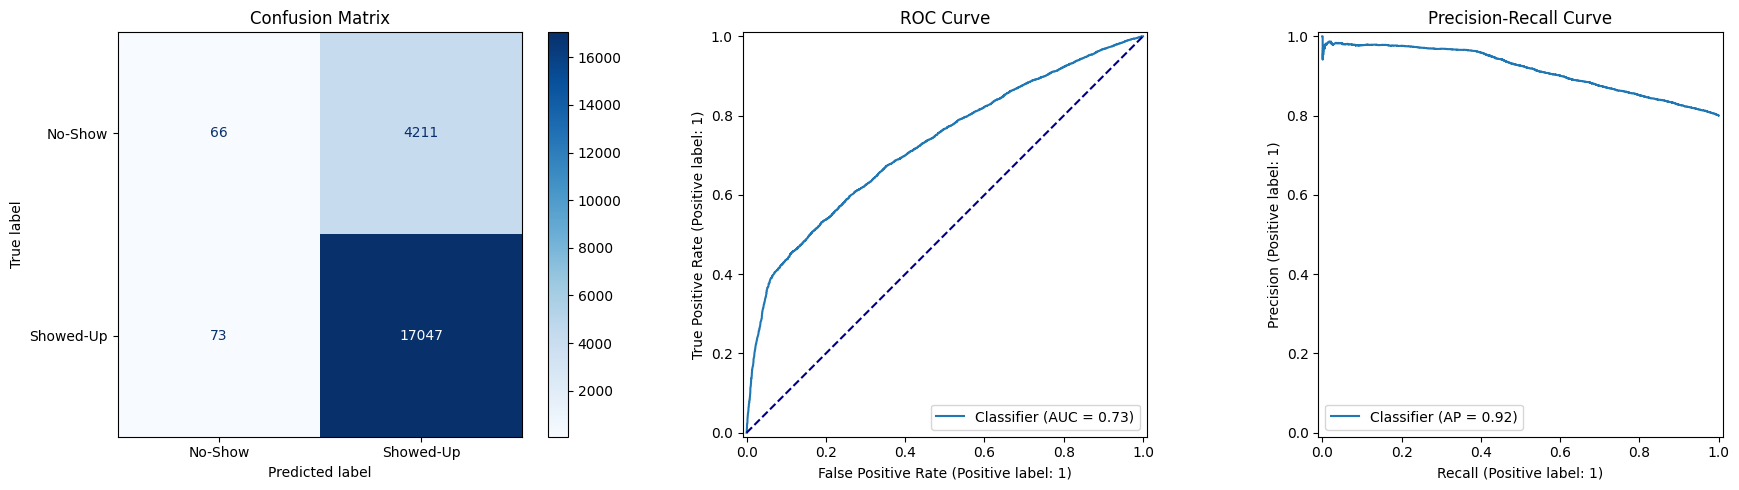

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, roc_auc_score, 
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

df_rf_clean = df_processed[df_processed['Date.diff'] >= 0].copy()

cols_to_drop = ['Showed_up', 'ScheduledDay', 'AppointmentDay', 'Neighbourhood']
if 'log_date_diff' in df_rf_clean.columns:
    cols_to_drop.append('log_date_diff')

X_rf = df_rf_clean.drop(columns=cols_to_drop)
y_rf = df_rf_clean['Showed_up']

X_train, X_test, y_train, y_test = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("--- SHAPE VERIFICATION ---")
print(f"y_test length: {len(y_test)}")
print(f"y_pred length: {len(y_pred_rf)}")
print(f"y_prob length: {len(y_prob_rf)}\n")


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, ax=axes[0], cmap='Blues', display_labels=['No-Show', 'Showed-Up']
)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test, y_prob_rf, ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_rf, ax=axes[2]
)
axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

## Random Forest

| Metryka | Wartość |
|----------|----------|
| Accuracy | 0.7998 |
| Precision | 0.4748 |
| Recall | 0.0154 |
| F1-score | 0.0299 |
| ROC-AUC | 0.7255 |

Interpretacja:

Model bardzo słabo wykrywa nieobecności.

Recall równy 1.54% oznacza, że model odnajduje jedynie niewielki odsetek rzeczywistych No-Show.

Jednocześnie ROC-AUC ≈ 0.73 wskazuje, że model posiada pewną zdolność separacji klas, lecz domyślny próg decyzyjny jest nieoptymalny.

--- REGRESSION METRICS ---
1. R-squared ($R^2$):             0.3811 (% of variance explained by model)
2. Mean Absolute Error (MAE):    0.8973 (Average distance off target)
3. Root Mean Squared Error (RMSE): 1.0783 (Penalizes larger mistakes heavier)



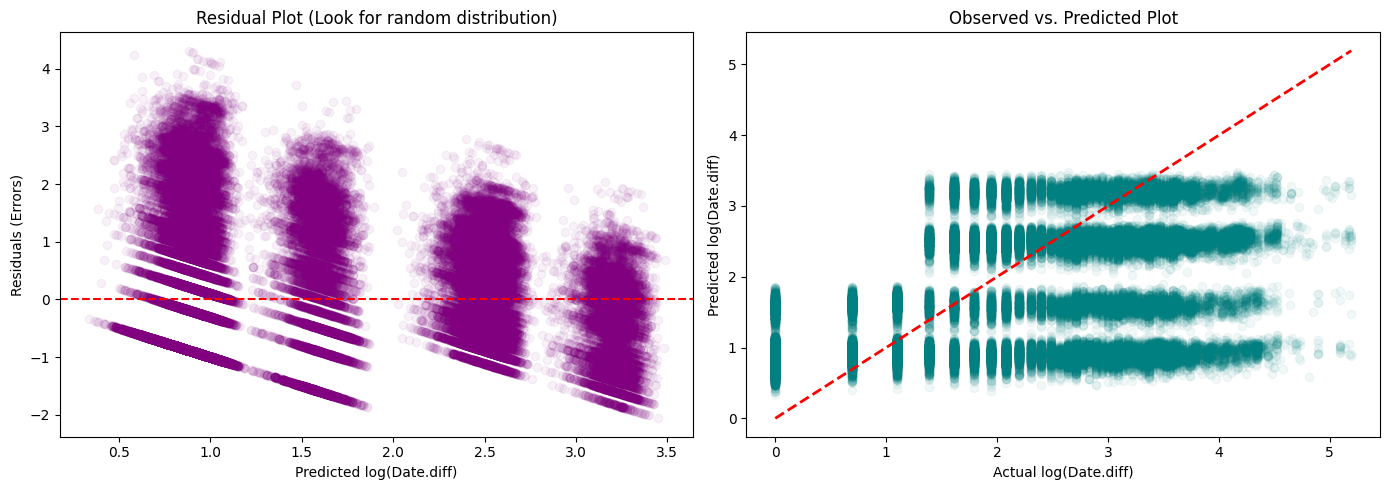

In [226]:
import statsmodels.api as sm
import numpy as np

y_lr_pred = lr_model.predict(X_lr)

r2 = lr_model.rsquared
mae = np.mean(np.abs(y_lr - y_lr_pred))
rmse = np.sqrt(np.mean((y_lr - y_lr_pred) ** 2))

print("--- REGRESSION METRICS ---")
print(f"1. R-squared ($R^2$):             {r2:.4f} (% of variance explained by model)")
print(f"2. Mean Absolute Error (MAE):    {mae:.4f} (Average distance off target)")
print(f"3. Root Mean Squared Error (RMSE): {rmse:.4f} (Penalizes larger mistakes heavier)\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_lr_pred, lr_model.resid, alpha=0.05, color='purple')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted log(Date.diff)')
axes[0].set_ylabel('Residuals (Errors)')
axes[0].set_title('Residual Plot (Look for random distribution)')

axes[1].scatter(y_lr, y_lr_pred, alpha=0.05, color='teal')
axes[1].plot([y_lr.min(), y_lr.max()], [y_lr.min(), y_lr.max()], 'r--', lw=2)
axes[1].set_xlabel('Actual log(Date.diff)')
axes[1].set_ylabel('Predicted log(Date.diff)')
axes[1].set_title('Observed vs. Predicted Plot')

plt.tight_layout()
plt.show()

## Porównanie modeli

| Model | Accuracy | ROC-AUC |
|---------|----------|----------|
| Naive Bayes | 0.768 | - |
| Random Forest | 0.800 | 0.726 |
| HistGradientBoosting | 0.800 | 0.720 |

Najlepsze wyniki uzyskały modele drzewiaste.

# 10. Podsumowanie i wnioski

Przeprowadzona analiza wykazała, że najważniejszym czynnikiem wpływającym na obecność pacjenta jest czas oczekiwania na wizytę.

Najważniejsze obserwacje:

1. Dłuższy czas oczekiwania znacząco zwiększa prawdopodobieństwo nieobecności.
2. Starsi pacjenci częściej realizują wizyty.
3. Płeć ma niewielkie znaczenie.
4. Choroby przewlekłe wykazują słabe zależności z obecnością.
5. Niepełnosprawność jest statystycznie istotna, lecz efekt praktyczny jest niewielki.
6. SMS nie powoduje wzrostu nieobecności – obserwowany efekt wynika z powiązania z czasem oczekiwania.
7. Największą wartość predykcyjną posiadają zmienne Date.diff oraz Age.

Modele klasyfikacyjne osiągnęły około 80% dokładności, jednak skuteczność wykrywania faktycznych nieobecności pozostaje niska. W przyszłych pracach warto zastosować:

- balansowanie klas (SMOTE, undersampling),
- ważenie klas,
- optymalizację progu decyzyjnego,
- dodatkowe cechy czasowe,
- bardziej zaawansowane modele gradient boosting.

Ostatecznie można stwierdzić, że organizacyjne aspekty procesu umawiania wizyt (przede wszystkim czas oczekiwania) mają większy wpływ na obecność pacjentów niż ich cechy zdrowotne czy demograficzne.